**Aluno:** Rafael da Silva Oliveira

**Matrícula:** CP3044564

---

# PROJETO DE COLETA DE DADOS
## Panorama do Mercado de Criptomoedas por meio da API CoinGecko

**Autor:** Rafael da Silva Oliveira
**Data:** 08/11/2026 (data da coleta)
**Disciplina:** Introdução à Ciência de Dados (Aula 4.2 - Processamento e Coleta de Dados)

---

## 1. OBJETIVO

Construir, a partir do zero, um dataset estruturado com as 100 maiores criptomoedas por capitalização de mercado, coletado por meio de API REST pública, e realizar sobre ele as etapas de limpeza, processamento, análise exploratória e documentação, conforme o fluxo de trabalho apresentado na Aula 4.2 (slides 1 a 9). O propósito analítico é caracterizar a concentração de mercado, a liquidez e a volatilidade de curto prazo (24 horas) desse conjunto de ativos.

**Tema e justificativa.** O tema "Criptomoedas" consta da lista de projetos sugeridos (`lista_projetos_sugeridos.csv`) com método API e dificuldade "Fácil". Foi escolhido porque: (i) a CoinGecko disponibiliza dados numéricos estruturados em JSON, adequados às etapas de limpeza e de análise exploratória; (ii) o endpoint utilizado funciona sem chave de acesso, o que dispensa o manuseio de credenciais; e (iii) os dados são de mercado, sem qualquer dado pessoal, o que afasta as restrições da LGPD (Lei 13.709/2018) discutidas no slide 21 da aula.

## 2. FONTES DE DADOS

| Fonte | URL | Método | Dados Coletados |
|-------|-----|--------|-----------------|
| CoinGecko API v3 (endpoint `/coins/markets`) | https://api.coingecko.com/api/v3/coins/markets | API (REST, JSON) | Nome, símbolo, ranking, preço em USD, variação percentual em 24 h, capitalização de mercado, volume negociado em 24 h, oferta circulante, máxima histórica (ATH) e data da última atualização das 100 maiores criptomoedas por capitalização |

*Fonte da documentação do endpoint:* CoinGecko API Documentation, "Coins List with Market Data" (https://docs.coingecko.com/v3.0.1/reference/coins-markets). O endpoint aceita os parâmetros `vs_currency` (obrigatório), `order`, `per_page` (1 a 250) e `page`.

## 3. METODOLOGIA
### 3.1 Coleta

A coleta foi feita com a biblioteca `requests`, por meio de uma única requisição GET ao endpoint `/coins/markets`, com os parâmetros `vs_currency=usd`, `order=market_cap_desc`, `per_page=100` e `page=1`. A requisição devolve diretamente uma lista de objetos JSON, um por moeda, o que torna desnecessário o web scraping (a escolha de API segue o critério de priorizar fontes estruturadas e documentadas).

Foram adotadas as boas práticas do slide 14 e as proteções do slide 5 da aula:

- **Tratamento de exceções** (`try/except`) em torno da requisição, com captura de falhas de rede e de decodificação de JSON (`JSONDecodeError`);
- **Tratamento do status 429** (limite de requisições excedido) com pausa por `time.sleep()` e nova tentativa, até três vezes;
- **Função modular e reutilizável** (`coletar_mercado`), que recebe como parâmetros a moeda de cotação e a quantidade de registros;
- **Preservação dos dados brutos**: a resposta original da API é gravada em `criptomoedas_bruto.json` antes de qualquer limpeza;
- **Validação da coleta**: verificação do status da resposta e do mínimo de 10 registros exigido na atividade (slide 4).

In [1]:
import json
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

URL_MERCADO = "https://api.coingecko.com/api/v3/coins/markets"
ARQUIVO_BRUTO = Path("criptomoedas_bruto.json")
MINIMO_REGISTROS = 10  # exigência da atividade (slide 4)


def coletar_mercado(moeda="usd", quantidade=100, tentativas=3, pausa=30):
    """Coleta as maiores criptomoedas por capitalização na CoinGecko (endpoint /coins/markets).

    Em caso de status 429 (rate limit), aguarda `pausa` segundos e tenta novamente (slide 5).
    Retorna a lista de dicionários obtida do JSON da API.
    """
    parametros = {
        "vs_currency": moeda,
        "order": "market_cap_desc",
        "per_page": quantidade,
        "page": 1,
    }
    for tentativa in range(1, tentativas + 1):
        try:
            resposta = requests.get(URL_MERCADO, params=parametros, timeout=30)
            print(f"Tentativa {tentativa}: HTTP {resposta.status_code}")

            if resposta.status_code == 429:
                print(f"Limite de requisições atingido; aguardando {pausa} s.")
                time.sleep(pausa)
                continue

            resposta.raise_for_status()
            return resposta.json()  # pode lançar JSONDecodeError se o corpo não for JSON

        except (requests.RequestException, ValueError) as erro:
            print(f"Falha na tentativa {tentativa}: {erro}")
            time.sleep(pausa)

    raise RuntimeError("Não foi possível coletar os dados após todas as tentativas.")


dados_crypto = coletar_mercado()
momento_coleta = datetime.now()

# Validação da coleta
assert isinstance(dados_crypto, list) and len(dados_crypto) >= MINIMO_REGISTROS, "Coleta insuficiente."
print(f"\nRegistros coletados: {len(dados_crypto)}")
print(f"Momento da coleta: {momento_coleta:%d/%m/%Y %H:%M:%S}")
print(f"Campos disponíveis por registro ({len(dados_crypto[0])}): {list(dados_crypto[0].keys())}")

# Preservação dos dados brutos antes da limpeza (slide 14)
ARQUIVO_BRUTO.write_text(json.dumps(dados_crypto, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Dados brutos salvos em: {ARQUIVO_BRUTO} ({ARQUIVO_BRUTO.stat().st_size / 1024:.1f} KB)")

Tentativa 1: HTTP 200

Registros coletados: 100
Momento da coleta: 08/11/2026 20:40:05
Campos disponíveis por registro (26): ['id', 'symbol', 'name', 'image', 'current_price', 'market_cap', 'market_cap_rank', 'fully_diluted_valuation', 'total_volume', 'high_24h', 'low_24h', 'price_change_24h', 'price_change_percentage_24h', 'market_cap_change_24h', 'market_cap_change_percentage_24h', 'circulating_supply', 'total_supply', 'max_supply', 'ath', 'ath_change_percentage', 'ath_date', 'atl', 'atl_change_percentage', 'atl_date', 'roi', 'last_updated']
Dados brutos salvos em: criptomoedas_bruto.json (97.0 KB)


**Estruturação em DataFrame.** Seguindo o padrão do slide 1, a lista `dados_crypto` é percorrida para extrair as propriedades relevantes (nome, símbolo em maiúsculas, preço, variação em 24 h, capitalização e volume), às quais foram acrescentados o ranking, a oferta circulante, a máxima histórica e a data de atualização. O método `.get()` é empregado para evitar `KeyError` caso algum campo esteja ausente (slide 5).

In [2]:
registros = []
for moeda in dados_crypto:
    registros.append({
        "name": moeda.get("name"),
        "symbol": (moeda.get("symbol") or "").upper(),
        "market_cap_rank": moeda.get("market_cap_rank"),
        "current_price": moeda.get("current_price"),
        "price_change_percentage_24h": moeda.get("price_change_percentage_24h"),
        "market_cap": moeda.get("market_cap"),
        "total_volume": moeda.get("total_volume"),
        "circulating_supply": moeda.get("circulating_supply"),
        "ath": moeda.get("ath"),
        "ath_change_percentage": moeda.get("ath_change_percentage"),
        "last_updated": moeda.get("last_updated"),
    })

df_bruto = pd.DataFrame(registros)

# Validação estrutural (slide 1)
print(df_bruto.shape)
df_bruto.head()

(100, 11)


,name,symbol,market_cap_rank,current_price,price_change_percentage_24h,market_cap,total_volume,circulating_supply,ath,ath_change_percentage,last_updated
0,Bitcoin,BTC,1,75185.000000,-0.72685,1511942918879,1.610140e+10,2.010967e+07,126080.00,-40.36727,2026-11-08T23:38:49.000Z
1,Ethereum,ETH,2,2143.230000,-4.01585,261904865681,7.879148e+09,1.222009e+08,4946.05,-56.66776,2026-11-08T23:38:49.000Z
2,Tether,USDT,3,0.999089,0.01711,176864245718,2.875755e+10,1.770255e+11,1.32,-24.48852,2026-11-08T23:38:49.000Z
3,BNB,BNB,4,687.600000,-1.05959,90427557934,6.696267e+08,1.315110e+08,1369.99,-49.80957,2026-11-08T23:38:49.000Z
4,XRP,XRP,5,1.120000,-3.31623,71241188208,1.535664e+09,6.351661e+10,3.65,-69.24029,2026-11-08T23:38:49.000Z


### 3.2 Limpeza

A limpeza seguiu as seis etapas do slide 6 da aula, aplicadas sobre uma cópia do DataFrame (os dados originais permanecem preservados no arquivo JSON bruto):

1. **Verificação de valores ausentes** com `isnull().sum()`;
2. **Tratamento dos ausentes**: eliminação (`dropna`) das linhas sem as variáveis essenciais à análise (nome, preço e capitalização de mercado); as variáveis complementares ausentes são mantidas como nulas (`NaN`), por não haver valor neutro adequado (o preenchimento com zero, por exemplo, distorceria médias e correlações);
3. **Conversão de tipos**: `to_numeric(errors="coerce")` nas colunas numéricas e `to_datetime` na data de atualização;
4. **Eliminação de duplicatas** com `drop_duplicates()`, tanto por linha completa quanto por símbolo;
5. **Renomeação** das colunas para português, com nomenclatura padronizada em minúsculas e sem acentos;
6. **Filtragem de consistência**: manutenção apenas de registros com preço e capitalização maiores que zero.

In [3]:
df = df_bruto.copy()
print(f"Registros antes da limpeza: {len(df)}")

# 1. Verificar valores ausentes
print("\nValores ausentes por coluna (antes):")
print(df.isnull().sum())

# 3. Converter tipos de dados (executado antes do tratamento para que valores inválidos virem NaN)
colunas_numericas = [
    "market_cap_rank", "current_price", "price_change_percentage_24h", "market_cap",
    "total_volume", "circulating_supply", "ath", "ath_change_percentage",
]
for coluna in colunas_numericas:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")
df["last_updated"] = pd.to_datetime(df["last_updated"], utc=True, errors="coerce").dt.tz_localize(None)

# 2. Tratar valores nulos: eliminar apenas linhas sem as variáveis essenciais
df = df.dropna(subset=["name", "current_price", "market_cap"])

# 4. Eliminar duplicatas (linha completa e símbolo repetido)
df = df.drop_duplicates()
df = df.drop_duplicates(subset=["symbol"], keep="first")

# 5. Renomear colunas (padronização e tradução)
df = df.rename(columns={
    "name": "nome",
    "symbol": "simbolo",
    "market_cap_rank": "ranking_capitalizacao",
    "current_price": "preco_usd",
    "price_change_percentage_24h": "variacao_24h_pct",
    "market_cap": "capitalizacao_usd",
    "total_volume": "volume_24h_usd",
    "circulating_supply": "oferta_circulante",
    "ath": "maxima_historica_usd",
    "ath_change_percentage": "distancia_maxima_pct",
    "last_updated": "atualizado_em",
})

# 6. Filtrar registros inconsistentes (preço e capitalização devem ser positivos)
df = df[(df["preco_usd"] > 0) & (df["capitalizacao_usd"] > 0)].reset_index(drop=True)

print(f"\nRegistros após a limpeza: {len(df)} (removidos: {len(df_bruto) - len(df)})")
print("\nValores ausentes por coluna (depois):")
print(df.isnull().sum())

Registros antes da limpeza: 100

Valores ausentes por coluna (antes):
name                           0
symbol                         0
market_cap_rank                0
current_price                  0
price_change_percentage_24h    0
market_cap                     0
total_volume                   0
circulating_supply             0
ath                            0
ath_change_percentage          0
last_updated                   0
dtype: int64

Registros após a limpeza: 100 (removidos: 0)

Valores ausentes por coluna (depois):
nome                     0
simbolo                  0
ranking_capitalizacao    0
preco_usd                0
variacao_24h_pct         0
capitalizacao_usd        0
volume_24h_usd           0
oferta_circulante        0
maxima_historica_usd     0
distancia_maxima_pct     0
atualizado_em            0
dtype: int64


### 3.3 Processamento

Após a limpeza, foram criadas variáveis derivadas que apoiam a análise exploratória:

- `giro_volume_capitalizacao`: razão entre o volume negociado em 24 h e a capitalização de mercado, indicador de liquidez relativa;
- `participacao_mercado_pct`: participação de cada moeda na capitalização total do conjunto coletado, usada para medir a concentração;
- `sentido_24h`: classificação qualitativa da variação em 24 h ("Alta" ou "Queda");
- `faixa_ranking`: agrupamento das moedas em "Top 10", "11 a 50" e "51 a 100", segundo o ranking de capitalização.

Por fim, o dataset é ordenado pelo ranking e exportado em CSV com `index=False` e `encoding="utf-8"` (slide 9).

In [4]:
# Variáveis derivadas
df["giro_volume_capitalizacao"] = df["volume_24h_usd"] / df["capitalizacao_usd"]
df["participacao_mercado_pct"] = df["capitalizacao_usd"] / df["capitalizacao_usd"].sum() * 100
df["sentido_24h"] = df["variacao_24h_pct"].apply(
    lambda v: None if pd.isna(v) else ("Alta" if v >= 0 else "Queda")
)
df["faixa_ranking"] = pd.cut(
    df["ranking_capitalizacao"], bins=[0, 10, 50, 100], labels=["Top 10", "11 a 50", "51 a 100"]
).astype(str)

# Ordenação e exportação
df = df.sort_values("ranking_capitalizacao").reset_index(drop=True)
ARQUIVO_CSV = Path("criptomoedas_dataset.csv")
df.to_csv(ARQUIVO_CSV, index=False, encoding="utf-8")
print(f"Dataset salvo em: {ARQUIVO_CSV} ({ARQUIVO_CSV.stat().st_size / 1024:.1f} KB)")

# Conferência de integridade: o CSV relido deve ter o mesmo formato do DataFrame em memória
df_conferencia = pd.read_csv(ARQUIVO_CSV, encoding="utf-8")
assert df_conferencia.shape == df.shape, "Inconsistência entre o CSV e o DataFrame."
print("Conferência de integridade: CSV relido com o mesmo formato do DataFrame.")
df.head()

Dataset salvo em: criptomoedas_dataset.csv (16.2 KB)
Conferência de integridade: CSV relido com o mesmo formato do DataFrame.


,nome,simbolo,ranking_capitalizacao,preco_usd,variacao_24h_pct,capitalizacao_usd,volume_24h_usd,oferta_circulante,maxima_historica_usd,distancia_maxima_pct,atualizado_em,giro_volume_capitalizacao,participacao_mercado_pct,sentido_24h,faixa_ranking
0,Bitcoin,BTC,1,75185.000000,-0.72685,1511942918879,1.610140e+10,2.010967e+07,126080.00,-40.36727,2026-11-08 23:38:49,0.010649,59.471401,Queda,Top 10
1,Ethereum,ETH,2,2143.230000,-4.01585,261904865681,7.879148e+09,1.222009e+08,4946.05,-56.66776,2026-11-08 23:38:49,0.030084,10.301877,Queda,Top 10
2,Tether,USDT,3,0.999089,0.01711,176864245718,2.875755e+10,1.770255e+11,1.32,-24.48852,2026-11-08 23:38:49,0.162597,6.956853,Alta,Top 10
3,BNB,BNB,4,687.600000,-1.05959,90427557934,6.696267e+08,1.315110e+08,1369.99,-49.80957,2026-11-08 23:38:49,0.007405,3.556916,Queda,Top 10
4,XRP,XRP,5,1.120000,-3.31623,71241188208,1.535664e+09,6.351661e+10,3.65,-69.24029,2026-11-08 23:38:49,0.021556,2.802231,Queda,Top 10


## 4. DATASET FINAL

Os valores desta seção são calculados a partir do dataset efetivamente gerado na execução do notebook.

In [5]:
from IPython.display import Markdown, display

tamanho_kb = ARQUIVO_CSV.stat().st_size / 1024
periodo_ini, periodo_fim = df["atualizado_em"].min(), df["atualizado_em"].max()

display(Markdown(
    f"- **Total de registros:** {df.shape[0]}\n"
    f"- **Total de colunas:** {df.shape[1]}\n"
    f"- **Período:** {periodo_ini:%d/%m/%Y %H:%M:%S} a {periodo_fim:%d/%m/%Y %H:%M:%S} (UTC; campo `atualizado_em`, "
    f"instantâneo de mercado de uma única coleta; a API atualiza cada moeda em momento próprio, daí o intervalo)\n"
    f"- **Tamanho do arquivo:** {tamanho_kb:.1f} KB (`{ARQUIVO_CSV}`)"
))

descricoes = {
    "nome": "Nome da criptomoeda",
    "simbolo": "Símbolo (ticker) em maiúsculas",
    "ranking_capitalizacao": "Posição pela capitalização de mercado (1 = maior)",
    "preco_usd": "Preço atual em dólares norte-americanos (USD)",
    "variacao_24h_pct": "Variação percentual do preço nas últimas 24 horas",
    "capitalizacao_usd": "Capitalização de mercado em USD (preço x oferta circulante)",
    "volume_24h_usd": "Volume total negociado nas últimas 24 horas em USD",
    "oferta_circulante": "Quantidade de unidades em circulação",
    "maxima_historica_usd": "Maior preço já registrado (ATH) em USD",
    "distancia_maxima_pct": "Variação percentual do preço atual em relação ao ATH",
    "atualizado_em": "Data e hora (UTC) da última atualização do registro na API",
    "giro_volume_capitalizacao": "Derivada: volume em 24 h dividido pela capitalização",
    "participacao_mercado_pct": "Derivada: participação na capitalização total do conjunto (%)",
    "sentido_24h": "Derivada: Alta (variação >= 0) ou Queda (variação < 0)",
    "faixa_ranking": "Derivada: Top 10, 11 a 50 ou 51 a 100",
}
linhas = ["### Colunas:", "| Coluna | Tipo | Descrição |", "|--------|------|-----------|"]
for coluna in df.columns:
    linhas.append(f"| `{coluna}` | {df[coluna].dtype} | {descricoes[coluna]} |")
display(Markdown("\n".join(linhas)))

- **Total de registros:** 100
- **Total de colunas:** 15
- **Período:** 08/11/2026 14:15:14 a 08/11/2026 23:38:49 (UTC; campo `atualizado_em`, instantâneo de mercado de uma única coleta; a API atualiza cada moeda em momento próprio, daí o intervalo)
- **Tamanho do arquivo:** 16.2 KB (`criptomoedas_dataset.csv`)

### Colunas:
| Coluna | Tipo | Descrição |
|--------|------|-----------|
| `nome` | object | Nome da criptomoeda |
| `simbolo` | object | Símbolo (ticker) em maiúsculas |
| `ranking_capitalizacao` | int64 | Posição pela capitalização de mercado (1 = maior) |
| `preco_usd` | float64 | Preço atual em dólares norte-americanos (USD) |
| `variacao_24h_pct` | float64 | Variação percentual do preço nas últimas 24 horas |
| `capitalizacao_usd` | int64 | Capitalização de mercado em USD (preço x oferta circulante) |
| `volume_24h_usd` | float64 | Volume total negociado nas últimas 24 horas em USD |
| `oferta_circulante` | float64 | Quantidade de unidades em circulação |
| `maxima_historica_usd` | float64 | Maior preço já registrado (ATH) em USD |
| `distancia_maxima_pct` | float64 | Variação percentual do preço atual em relação ao ATH |
| `atualizado_em` | datetime64[ns] | Data e hora (UTC) da última atualização do registro na API |
| `giro_volume_capitalizacao` | float64 | Derivada: volume em 24 h dividido pela capitalização |
| `participacao_mercado_pct` | float64 | Derivada: participação na capitalização total do conjunto (%) |
| `sentido_24h` | object | Derivada: Alta (variação >= 0) ou Queda (variação < 0) |
| `faixa_ranking` | object | Derivada: Top 10, 11 a 50 ou 51 a 100 |

## 5. ANÁLISE EXPLORATÓRIA
### 5.1 Estatísticas Descritivas

São aplicadas as funções de diagnóstico rápido do slide 7: `shape`, `dtypes`, `describe()`, `isnull().sum()` e `columns.tolist()`.

In [6]:
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 200)

print("Dimensão (linhas, colunas):", df.shape)
print("\nColunas:", df.columns.tolist())
print("\nValores ausentes por coluna:")
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().sum().sum() else "Nenhum valor ausente.")

colunas_resumo = ["preco_usd", "variacao_24h_pct", "capitalizacao_usd", "volume_24h_usd",
                  "giro_volume_capitalizacao", "distancia_maxima_pct"]
print("\nEstatísticas descritivas:")
df[colunas_resumo].describe().T

Dimensão (linhas, colunas): (100, 15)

Colunas: ['nome', 'simbolo', 'ranking_capitalizacao', 'preco_usd', 'variacao_24h_pct', 'capitalizacao_usd', 'volume_24h_usd', 'oferta_circulante', 'maxima_historica_usd', 'distancia_maxima_pct', 'atualizado_em', 'giro_volume_capitalizacao', 'participacao_mercado_pct', 'sentido_24h', 'faixa_ranking']

Valores ausentes por coluna:
Nenhum valor ausente.

Estatísticas descritivas:


,count,mean,std,min,25%,50%,75%,max
preco_usd,100.00,893.15,"7,529.74",0.00,0.32,1.00,6.87,"75,185.00"
variacao_24h_pct,100.00,-1.91,2.19,-11.24,-3.12,-2.02,-0.00,3.23
capitalizacao_usd,100.00,"25,423,024,952.10","153,921,387,172.92","515,084,771.00","929,804,206.50","1,775,203,923.00","3,710,397,766.50","1,511,942,918,879.00"
volume_24h_usd,100.00,"707,364,714.39","3,399,602,363.63",0.00,"7,809,812.75","35,938,780.50","125,906,262.50","28,757,554,957.00"
giro_volume_capitalizacao,100.00,0.03,0.04,0.00,0.01,0.02,0.04,0.18
distancia_maxima_pct,100.00,-56.57,35.27,-99.68,-87.62,-67.99,-24.19,0.00


In [7]:
# Indicadores de concentração e de sentido do mercado
total_capitalizacao = df["capitalizacao_usd"].sum()
top1 = df.iloc[0]
top3 = df.head(3)["participacao_mercado_pct"].sum()
top10 = df.head(10)["participacao_mercado_pct"].sum()

print(f"Capitalização total do conjunto: US$ {total_capitalizacao / 1e12:,.3f} trilhões")
print(f"Participação de {top1['nome']}: {top1['participacao_mercado_pct']:.1f}%")
print(f"Participação das 3 maiores: {top3:.1f}%")
print(f"Participação das 10 maiores: {top10:.1f}%")

print("\nSentido da variação em 24 h:")
print(df["sentido_24h"].value_counts(dropna=False).to_string())
print(f"\nVariação mediana em 24 h: {df['variacao_24h_pct'].median():.2f}%")

print("\nCapitalização e variação média por faixa de ranking:")
print(df.groupby("faixa_ranking", sort=False)[["capitalizacao_usd", "variacao_24h_pct", "giro_volume_capitalizacao"]]
        .agg({"capitalizacao_usd": "sum", "variacao_24h_pct": "mean", "giro_volume_capitalizacao": "mean"}))

print("\nCinco maiores altas e quedas em 24 h:")
extremos = pd.concat([df.nlargest(5, "variacao_24h_pct"), df.nsmallest(5, "variacao_24h_pct")])
print(extremos[["nome", "simbolo", "ranking_capitalizacao", "variacao_24h_pct"]].to_string(index=False))

import numpy as np
com_volume = df[df["volume_24h_usd"] > 0]  # log10 não está definido para volume igual a zero
print(f"\nMoedas com volume igual a zero em 24 h: {(df['volume_24h_usd'] == 0).sum()}")
print(f"Correlação (Pearson) entre log10(capitalização) e log10(volume), {len(com_volume)} moedas com volume positivo: "
      f"{np.corrcoef(np.log10(com_volume['capitalizacao_usd']), np.log10(com_volume['volume_24h_usd']))[0, 1]:.3f}")
print(f"Giro mediano (volume/capitalização): {df['giro_volume_capitalizacao'].median():.3f}")
print("\nMaiores giros:")
print(df.nlargest(3, "giro_volume_capitalizacao")[["nome", "giro_volume_capitalizacao"]].to_string(index=False))
print(f"\nMoedas mais de 50% abaixo da máxima histórica: {(df['distancia_maxima_pct'] < -50).sum()}")
print(f"Distância mediana em relação à máxima histórica: {df['distancia_maxima_pct'].median():.1f}%")

Capitalização total do conjunto: US$ 2.542 trilhões
Participação de Bitcoin: 59.5%
Participação das 3 maiores: 76.7%
Participação das 10 maiores: 91.0%

Sentido da variação em 24 h:
Queda    76
Alta     24

Variação mediana em 24 h: -2.02%

Capitalização e variação média por faixa de ranking:
               capitalizacao_usd  variacao_24h_pct  giro_volume_capitalizacao
faixa_ranking                                                                
Top 10             2313215753225             -1.24                       0.04
11 a 50             178315586155             -1.60                       0.03
51 a 100             50771155830             -2.29                       0.03

Cinco maiores altas e quedas em 24 h:
        nome    simbolo  ranking_capitalizacao  variacao_24h_pct
        Pepe       PEPE                     43              3.23
Figure Heloc FIGR_HELOC                      9              2.15
       Quant        QNT                     34              1.01
        Gate     

### 5.2 Visualizações

Foram geradas três visualizações com `matplotlib.pyplot`, conforme o slide 8 (gráfico de barras e gráfico de dispersão), além de um histograma: (i) as dez maiores criptomoedas por capitalização de mercado; (ii) a relação entre capitalização e volume negociado, em escala logarítmica por causa da forte assimetria das variáveis; e (iii) a distribuição da variação percentual em 24 h. No gráfico de dispersão, moedas com volume igual a zero não são representáveis em escala logarítmica e ficam fora da figura (a quantidade é informada na seção 5.1). Os gráficos são gravados em arquivos PNG.

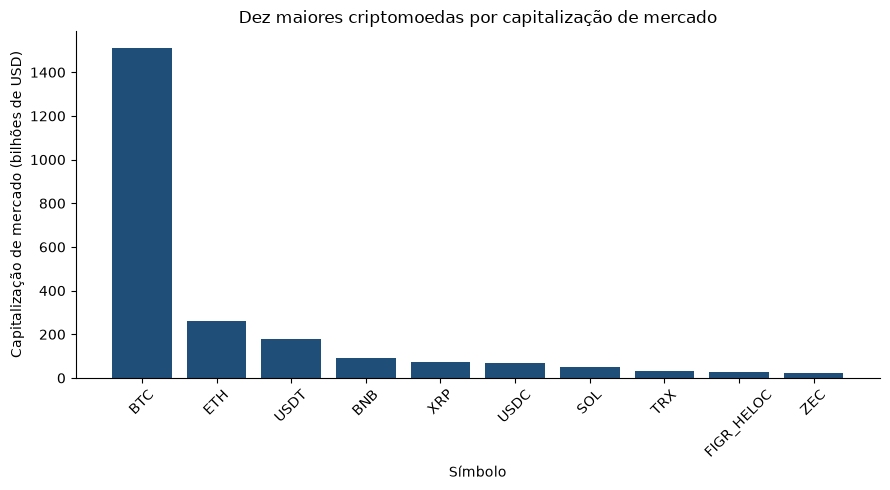

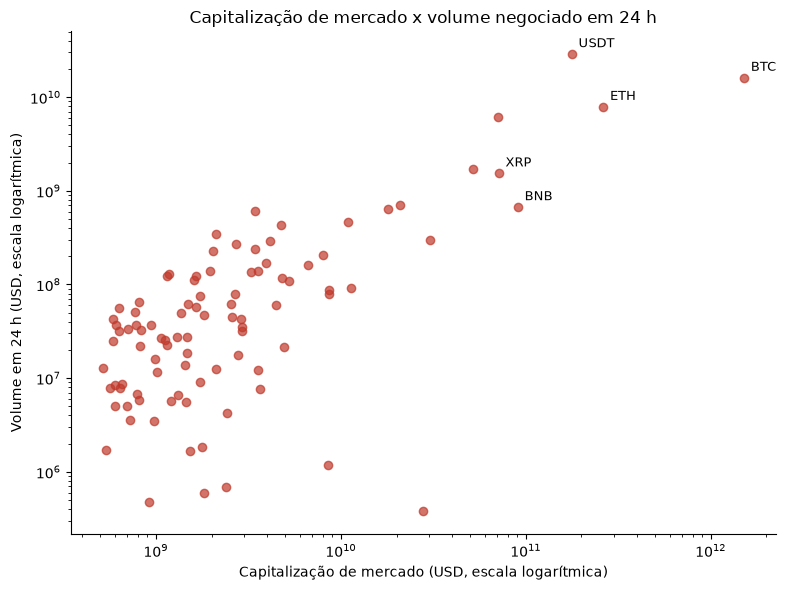

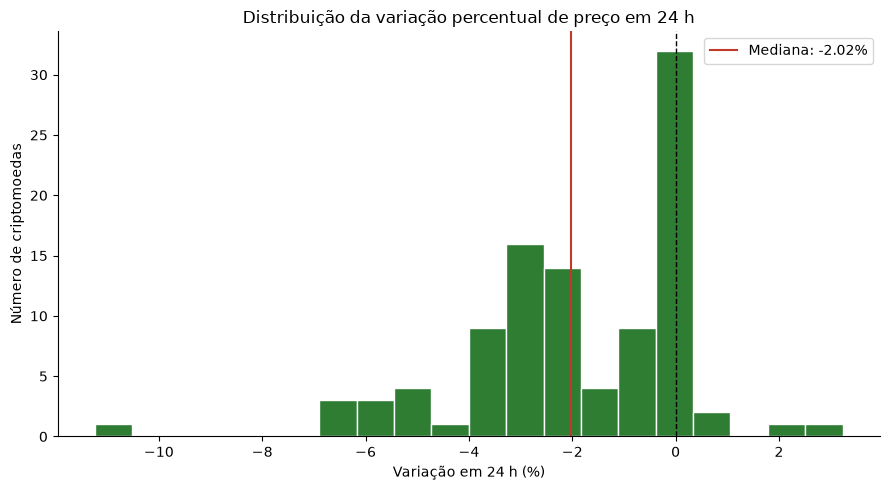

In [8]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

# Gráfico 1: barras - 10 maiores capitalizações
top10_df = df.head(10)
plt.figure(figsize=(9, 5))
plt.bar(top10_df["simbolo"], top10_df["capitalizacao_usd"] / 1e9, color="#1f4e79")
plt.title("Dez maiores criptomoedas por capitalização de mercado")
plt.xlabel("Símbolo")
plt.ylabel("Capitalização de mercado (bilhões de USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("grafico_top10_capitalizacao.png", dpi=150)
plt.show()

# Gráfico 2: dispersão - capitalização x volume (escala logarítmica)
plt.figure(figsize=(8, 6))
plt.scatter(df["capitalizacao_usd"], df["volume_24h_usd"], color="#c0392b", alpha=0.7)
for _, linha in df.head(5).iterrows():
    plt.annotate(linha["simbolo"], (linha["capitalizacao_usd"], linha["volume_24h_usd"]),
                 textcoords="offset points", xytext=(5, 5), fontsize=9)
plt.xscale("log")
plt.yscale("log")
plt.title("Capitalização de mercado x volume negociado em 24 h")
plt.xlabel("Capitalização de mercado (USD, escala logarítmica)")
plt.ylabel("Volume em 24 h (USD, escala logarítmica)")
plt.tight_layout()
plt.savefig("grafico_capitalizacao_volume.png", dpi=150)
plt.show()

# Gráfico 3: histograma - variação percentual em 24 h
plt.figure(figsize=(9, 5))
plt.hist(df["variacao_24h_pct"].dropna(), bins=20, color="#2e7d32", edgecolor="white")
plt.axvline(0, color="black", linewidth=1, linestyle="--")
plt.axvline(df["variacao_24h_pct"].median(), color="#c0392b", linewidth=1.5,
            label=f"Mediana: {df['variacao_24h_pct'].median():.2f}%")
plt.title("Distribuição da variação percentual de preço em 24 h")
plt.xlabel("Variação em 24 h (%)")
plt.ylabel("Número de criptomoedas")
plt.legend()
plt.tight_layout()
plt.savefig("grafico_variacao_24h.png", dpi=150)
plt.show()

## 6. INSIGHTS

Os números abaixo correspondem à coleta de 08/11/2026 e são conferíveis nas saídas das seções 5.1 e 5.2.

1. **Concentração extrema de mercado.** O Bitcoin responde por 59,5% da capitalização total das 100 moedas coletadas (US$ 2,542 trilhões); com o Ethereum, o percentual sobe para cerca de 69,8%, e as 10 maiores moedas somam 91,0%. As 90 demais dividem apenas 9,0% do valor, o que se reflete no gráfico de barras: a capitalização do Bitcoin é mais de cinco vezes a do Ethereum, segundo colocado.
2. **Liquidez acompanha o tamanho, com dispersão relevante.** Em escala logarítmica, capitalização e volume negociado apresentam correlação de Pearson de 0,669 (95 moedas com volume positivo). O giro mediano (volume diário dividido pela capitalização) é de 0,020, mas os maiores giros pertencem a USD1 (0,18), Pepe (0,17) e Tether (0,16), isto é, a stablecoins e a uma moeda de perfil especulativo, e não necessariamente às de maior capitalização. Cinco ativos registraram volume igual a zero em 24 h.
3. **Dia de queda generalizada e queda mais intensa nas faixas menores.** Em 76 das 100 moedas a variação em 24 h foi negativa, com mediana de -2,02%. A variação média foi de -1,24% no grupo Top 10, -1,60% no grupo 11 a 50 e -2,29% no grupo 51 a 100, o que sugere maior sensibilidade das moedas de menor capitalização. Como se trata de um único dia, esse resultado é descritivo e não permite concluir que o padrão se repita.
4. **Mercado distante dos máximos históricos.** 62 das 100 moedas estão mais de 50% abaixo da máxima histórica, e a distância mediana é de -68,0%.

## 7. LIMITAÇÕES

- **Instantâneo, não série temporal.** O dataset reflete o mercado no momento da coleta; o conteúdo varia a cada execução, de modo que os valores numéricos citados neste relatório não são reproduzíveis exatamente. Por esse motivo os dados brutos (`criptomoedas_bruto.json`) e o CSV foram preservados.
- **Amostra restrita às 100 maiores moedas.** Não representa o universo de milhares de criptoativos; a conclusão sobre concentração refere-se apenas a esse recorte.
- **Dependência de uma única fonte.** Preços, volumes e capitalizações são agregados pela CoinGecko; não houve validação cruzada com outra fonte, e os critérios de agregação são definidos pelo provedor.
- **Variação de apenas 24 h.** Horizonte curto, sujeito a ruído; não permite inferir tendência. A análise é descritiva e não constitui recomendação de investimento.
- **Limites da API sem chave.** O uso sem chave é limitado por endereço IP, em cota compartilhada com os demais usuários desse IP, e chamadas com erro 4xx/5xx também contam para o limite (CoinGecko, "Common Errors & Rate Limit").

## 8. PRÓXIMOS PASSOS

- Agendar a coleta periódica (por exemplo, diária), com `cron`, Agendador de Tarefas do Windows ou GitHub Actions (slide 20), para formar uma série temporal e permitir análise de tendência e de volatilidade.
- Complementar o dataset com o histórico de preços (endpoint de gráfico de mercado da própria API) e com uma segunda fonte, para validação cruzada.
- Aprofundar a limpeza (tratamento de outliers, normalização e padronização de variáveis), tema das Aulas 5 e 6, e elaborar a matriz de correlação da Aula 7.
- Publicar o código, o dataset e um `README` estruturado em repositório público no GitHub, conforme a tarefa de casa (slide 29).

## 9. CÓDIGO

- **Notebook:** `Exercicios_Aula4.ipynb` (este arquivo), com todo o código executável.
- **Arquivos gerados na mesma pasta:** `criptomoedas_bruto.json` (dados brutos), `criptomoedas_dataset.csv` (dataset final), `documentacao.md` (documentação em Markdown, slide 9) e os três gráficos em PNG.
- **Repositório GitHub:** https://github.com/Rafa516/coleta-dados-criptomoedas-coingecko (código, dataset, documentação e README, conforme o slide 22).

## 10. REFERÊNCIAS

- PEREIRA, Danilo. **Aula 4.2: Processamento e Coleta de Dados.** Introdução à Ciência de Dados, Pós-graduação em Ciência de Dados, IFSP. Material em PDF (`Aula 4.2_Processamento e Coleta de Dados.pdf`), slides 1 a 10, 14, 20, 21, 25 e 29.
- COINGECKO. **Coins List with Market Data (endpoint /coins/markets).** CoinGecko API Documentation. Disponível em: https://docs.coingecko.com/v3.0.1/reference/coins-markets. Acesso em: 08 nov. 2026.
- COINGECKO. **Common Errors & Rate Limit.** CoinGecko API Documentation. Disponível em: https://docs.coingecko.com/docs/common-errors-rate-limit. Acesso em: 08 nov. 2026. (Limite de 100 chamadas por minuto no plano Demo; no uso sem chave, o limite é aplicado por endereço IP; erro 429 em caso de excesso.)
- BRASIL. **Lei nº 13.709, de 14 de agosto de 2018** (Lei Geral de Proteção de Dados Pessoais), citada no slide 21 da Aula 4.2.
- Arquivo `lista_projetos_sugeridos.csv`, fornecido com a atividade (tema "Criptomoedas", fonte CoinGecko API, método API, dificuldade "Fácil").

## ETAPA FINAL: DOCUMENTAÇÃO EM MARKDOWN E CHECKLIST

Conforme o slide 9, o script a seguir gera o arquivo `documentacao.md`, contendo tema, data, URLs, propósito, dicionário de dados, estatísticas gerais e insights. Em seguida é apresentado o checklist de autoavaliação do projeto (slide 10).

In [9]:
resumo_estatistico = df[["preco_usd", "variacao_24h_pct", "capitalizacao_usd", "volume_24h_usd"]].describe().T
tabela_dicionario = "\n".join(
    f"| `{coluna}` | {df[coluna].dtype} | {descricoes[coluna]} |" for coluna in df.columns
)

documentacao = f"""# Documentação do Projeto

- **Tema:** Panorama do mercado de criptomoedas (CoinGecko API)
- **Autor:** Rafael da Silva Oliveira (CP3044564)
- **Data da coleta:** {momento_coleta:%d/%m/%Y %H:%M:%S}
- **Fonte / URL:** {URL_MERCADO} (parâmetros: vs_currency=usd, order=market_cap_desc, per_page=100, page=1)
- **Documentação da fonte:** https://docs.coingecko.com/v3.0.1/reference/coins-markets

## Propósito
Caracterizar a concentração de mercado, a liquidez e a volatilidade de curto prazo (24 h) das 100 maiores criptomoedas por capitalização.

## Dicionário de dados
| Coluna | Tipo | Descrição |
|--------|------|-----------|
{tabela_dicionario}

## Estatísticas gerais
- Registros: {df.shape[0]} | Colunas: {df.shape[1]}
- Capitalização total do conjunto: US$ {total_capitalizacao / 1e12:,.3f} trilhões
- Participação de {top1['nome']}: {top1['participacao_mercado_pct']:.1f}% | 10 maiores: {top10:.1f}%
- Variação mediana em 24 h: {df['variacao_24h_pct'].median():.2f}%

```
{resumo_estatistico.to_string()}
```

## Insights
Ver a seção 6 do notebook Exercicios_Aula4.ipynb.
"""
Path("documentacao.md").write_text(documentacao, encoding="utf-8")
print("Arquivo gerado: documentacao.md")

# Checklist de autoavaliação (slide 10): cada item é verificado em código quando possível
checklist = {
    "Tema e justificativa definidos": True,
    "Fontes de dados identificadas": True,
    "Coleta de dados planejada": True,
    "Código implementado": True,
    "Mínimo de 10 registros coletados": len(dados_crypto) >= MINIMO_REGISTROS,
    "Dados limpos (tipos e ausentes)": df[["preco_usd", "capitalizacao_usd"]].isnull().sum().sum() == 0,
    "DataFrame final criado": isinstance(df, pd.DataFrame) and not df.empty,
    "Análise exploratória realizada": True,
    "Pelo menos um gráfico gerado": Path("grafico_top10_capitalizacao.png").exists(),
    "Dataset salvo em formato CSV": ARQUIVO_CSV.exists(),
    "Todo o processo documentado": Path("documentacao.md").exists(),
    "Notebook salvo com sucesso": True,
}
for item, ok in checklist.items():
    print(f"[{'x' if ok else ' '}] {item}")
pontos = sum(checklist.values())
classe = "EXCELENTE" if pontos >= 10 else "MUITO BOM" if pontos >= 7 else "Exige revisão do projeto"
print(f"\nPontuação: {pontos}/12 -> {classe}")

Arquivo gerado: documentacao.md
[x] Tema e justificativa definidos
[x] Fontes de dados identificadas
[x] Coleta de dados planejada
[x] Código implementado
[x] Mínimo de 10 registros coletados
[x] Dados limpos (tipos e ausentes)
[x] DataFrame final criado
[x] Análise exploratória realizada
[x] Pelo menos um gráfico gerado
[x] Dataset salvo em formato CSV
[x] Todo o processo documentado
[x] Notebook salvo com sucesso

Pontuação: 12/12 -> EXCELENTE
